In [ ]:
#EDA 사전세팅
%matplotlib inline

import time
import os

os.environ['KMP_WARNINGS'] = 'off'
from functools import reduce
import matplotlib as mpl
from datetime import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns  #데이터 시각화

pd.set_option('display.max_columns', None) ## 모든 열을 출력한다.

In [ ]:
# 코렙에서 한글 깨짐 현상 있을때 설치 후 밑코드로 해결완료
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf
plt.rc('font', family='NanumBarunGothic')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 18 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/

In [ ]:
train_df = pd.read_csv('/content/kbo_train.csv')
test_df = pd.read_csv('/content/kbo_test.csv')

In [ ]:
train_df

,연도,이름,나이,팀,포지션,WAR,oWAR,dWAR,G,PA,ePA,AB,R,H,2B,3B,HR,TB,RBI,SB,CS,BB,HP,IB,SO,GDP,SH,SF,AVG,OBP,SLG,OPS,R/ePA,wRC+,wOBA,EV,sd(LA),SwSp%,Chase%,Whiff%,CSW%,Zone Judgement,HardHit%,Barrel%,Barrel/PA,ICR%,IPA%,xBA,xwOBAcon,xwOBA
0,2021,강민호,35,삼성,C,3.94,3.91,0.03,123,462,460,406,55,118,22,0,18,194,67,0,0,45,4,4,53,18,0,7,0.291,0.361,0.478,0.839,0.156,122.4,0.375,133.5,26.1,33.6,27.6,16.9,24.4,70,34.3,6.4,3.4,40.3,44.9,0.298,0.388,0.374
1,2022,강민호,36,삼성,C,1.81,1.86,-0.04,130,444,441,396,38,102,19,1,13,162,66,0,0,41,3,4,58,21,1,3,0.258,0.330,0.409,0.739,0.122,102.0,0.336,134.3,25.9,33.4,27.4,18.1,27.2,63,38.1,6.4,3.3,37.8,40.8,0.279,0.367,0.348
2,2023,강민호,37,삼성,C,3.30,3.60,-0.30,125,495,492,434,60,126,19,0,16,193,77,6,1,49,6,4,65,17,1,5,0.290,0.366,0.445,0.811,0.149,123.5,0.368,136.2,24.0,40.0,28.7,20.0,26.4,55,39.5,7.1,3.4,40.4,43.9,0.302,0.400,0.375
3,2021,강백호,21,KT,1B,6.80,6.72,0.08,142,627,620,516,76,179,40,1,16,269,102,10,5,103,0,10,85,7,0,8,0.347,0.450,0.521,0.971,0.212,168.7,0.442,138.9,25.4,31.4,26.4,17.8,24.0,59,44.9,7.7,3.7,41.3,47.5,0.296,0.410,0.397
4,2022,강백호,22,KT,DH,-0.07,-0.19,0.13,62,264,261,237,24,58,12,0,6,88,29,0,0,23,1,2,44,6,1,2,0.245,0.312,0.371,0.683,0.103,85.4,0.312,137.1,26.1,31.7,30.9,19.6,29.0,33,37.1,10.9,5.5,32.0,34.5,0.248,0.356,0.324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,2022,황대인,25,KIA,1B,0.18,0.35,-0.17,129,524,523,476,40,122,27,0,14,191,91,0,0,36,7,2,92,20,0,5,0.256,0.315,0.401,0.716,0.113,98.8,0.323,132.2,25.1,34.9,38.8,20.3,24.9,23,27.7,4.0,2.1,30.7,32.7,0.239,0.325,0.296
314,2023,황대인,26,KIA,1B,-0.27,-0.48,0.21,60,199,198,174,19,37,4,0,5,56,26,0,0,18,4,2,50,6,0,3,0.213,0.296,0.322,0.618,0.081,70.5,0.291,136.5,22.1,33.5,33.5,26.1,28.8,38,34.6,8.8,3.4,37.9,37.5,0.231,0.372,0.309
315,2021,황재균,33,KT,3B,2.83,2.41,0.41,117,507,505,453,74,132,16,2,10,182,56,11,4,46,3,1,92,11,1,4,0.291,0.358,0.402,0.760,0.135,107.9,0.348,135.6,25.7,34.3,29.2,20.3,27.3,46,36.1,4.0,2.2,38.7,39.1,0.276,0.380,0.340
316,2022,황재균,34,KT,3B,1.81,2.07,-0.26,141,581,578,519,59,136,25,3,10,197,64,6,3,53,5,5,99,17,2,2,0.262,0.335,0.380,0.715,0.117,97.1,0.330,134.7,28.2,34.8,31.1,18.8,25.4,59,34.1,4.9,2.3,35.8,37.1,0.252,0.348,0.320


In [ ]:
#1B 가져오기
train_df["1B"] = train_df["H"] - train_df["2B"] - train_df["3B"] - train_df["HR"]
test_df["1B"] = test_df["H"] - test_df["2B"] - test_df["3B"] - test_df["HR"]

In [ ]:
# 기존 df_p에 "1B" 열 추가
train_df["1B"] = train_df["1B"]
test_df["1B"] = test_df["1B"]

In [ ]:
#R/ePA : R, ePA로 계산 가능 -> 제거 & 칼럼 정리
train_df = train_df.drop(columns=['연도', '이름','팀','포지션','WAR','R/ePA', 'TB', 'HP','2B','3B','HR','H'])

In [ ]:
#R/ePA : R, ePA로 계산 가능 -> 제거 & 칼럼 정리
test_df = test_df.drop(columns=['연도', '이름','팀','포지션','WAR','R/ePA', 'TB', 'HP','2B','3B','HR','H'])

In [ ]:
train_df = train_df[train_df['PA'] >= 30]
test_df = test_df[test_df['PA'] >= 30]

In [ ]:
train_df

,나이,oWAR,dWAR,G,PA,ePA,AB,R,RBI,SB,CS,BB,IB,SO,GDP,SH,SF,AVG,OBP,SLG,OPS,wRC+,wOBA,EV,sd(LA),SwSp%,Chase%,Whiff%,CSW%,Zone Judgement,HardHit%,Barrel%,Barrel/PA,ICR%,IPA%,xBA,xwOBAcon,xwOBA,1B
0,35,3.91,0.03,123,462,460,406,55,67,0,0,45,4,53,18,0,7,0.291,0.361,0.478,0.839,122.4,0.375,133.5,26.1,33.6,27.6,16.9,24.4,70,34.3,6.4,3.4,40.3,44.9,0.298,0.388,0.374,78
1,36,1.86,-0.04,130,444,441,396,38,66,0,0,41,4,58,21,1,3,0.258,0.330,0.409,0.739,102.0,0.336,134.3,25.9,33.4,27.4,18.1,27.2,63,38.1,6.4,3.3,37.8,40.8,0.279,0.367,0.348,69
2,37,3.60,-0.30,125,495,492,434,60,77,6,1,49,4,65,17,1,5,0.290,0.366,0.445,0.811,123.5,0.368,136.2,24.0,40.0,28.7,20.0,26.4,55,39.5,7.1,3.4,40.4,43.9,0.302,0.400,0.375,91
3,21,6.72,0.08,142,627,620,516,76,102,10,5,103,10,85,7,0,8,0.347,0.450,0.521,0.971,168.7,0.442,138.9,25.4,31.4,26.4,17.8,24.0,59,44.9,7.7,3.7,41.3,47.5,0.296,0.410,0.397,122
4,22,-0.19,0.13,62,264,261,237,24,29,0,0,23,2,44,6,1,2,0.245,0.312,0.371,0.683,85.4,0.312,137.1,26.1,31.7,30.9,19.6,29.0,33,37.1,10.9,5.5,32.0,34.5,0.248,0.356,0.324,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,25,0.35,-0.17,129,524,523,476,40,91,0,0,36,2,92,20,0,5,0.256,0.315,0.401,0.716,98.8,0.323,132.2,25.1,34.9,38.8,20.3,24.9,23,27.7,4.0,2.1,30.7,32.7,0.239,0.325,0.296,81
314,26,-0.48,0.21,60,199,198,174,19,26,0,0,18,2,50,6,0,3,0.213,0.296,0.322,0.618,70.5,0.291,136.5,22.1,33.5,33.5,26.1,28.8,38,34.6,8.8,3.4,37.9,37.5,0.231,0.372,0.309,28
315,33,2.41,0.41,117,507,505,453,74,56,11,4,46,1,92,11,1,4,0.291,0.358,0.402,0.760,107.9,0.348,135.6,25.7,34.3,29.2,20.3,27.3,46,36.1,4.0,2.2,38.7,39.1,0.276,0.380,0.340,104
316,34,2.07,-0.26,141,581,578,519,59,64,6,3,53,5,99,17,2,2,0.262,0.335,0.380,0.715,97.1,0.330,134.7,28.2,34.8,31.1,18.8,25.4,59,34.1,4.9,2.3,35.8,37.1,0.252,0.348,0.320,98


In [ ]:
test_df

,나이,oWAR,dWAR,G,PA,ePA,AB,R,RBI,SB,CS,BB,IB,SO,GDP,SH,SF,AVG,OBP,SLG,OPS,wRC+,wOBA,EV,sd(LA),SwSp%,Chase%,Whiff%,CSW%,Zone Judgement,HardHit%,Barrel%,Barrel/PA,ICR%,IPA%,xBA,xwOBAcon,xwOBA,1B
0,38,3.02,0.30,136,452,450,403,48,77,3,0,35,2,52,17,0,6,0.303,0.365,0.496,0.861,115.6,0.388,136.7,24.6,33.5,27.6,15.7,23.8,73,37.5,5.6,3.7,39.8,43.0,0.309,0.386,0.381,83
1,24,2.46,-0.34,144,614,612,550,92,96,6,2,59,4,127,6,0,2,0.289,0.360,0.480,0.840,112.3,0.380,140.2,24.4,29.7,32.7,23.8,30.7,21,44.7,11.6,6.7,43.7,40.4,0.284,0.451,0.385,106
2,29,2.90,0.81,140,566,561,521,81,81,16,5,32,4,158,8,2,4,0.280,0.328,0.476,0.804,104.3,0.363,139.0,23.2,39.6,35.8,31.3,31.4,31,40.4,10.4,5.5,41.2,34.3,0.257,0.450,0.342,87
3,30,-0.26,0.10,16,31,30,27,4,2,0,0,3,0,5,0,1,0,0.185,0.267,0.185,0.452,16.4,0.222,129.1,28.6,7.7,41.3,11.1,24.3,5,30.8,0.0,0.0,30.8,35.7,0.240,0.269,0.270,5
5,34,0.06,-0.09,28,36,36,32,3,4,0,0,4,0,6,2,0,0,0.250,0.333,0.406,0.739,92.0,0.384,122.3,22.3,0.0,40.0,29.5,30.9,25,16.7,16.7,3.7,16.7,23.5,0.189,0.335,0.329,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,29,-0.22,-0.30,40,76,76,73,10,3,2,1,2,0,22,2,0,0,0.247,0.276,0.329,0.605,50.3,0.248,116.6,20.6,37.5,40.4,19.3,26.0,15,25.0,0.0,0.0,37.5,32.0,0.259,0.358,0.290,13
101,34,0.43,-0.67,132,523,519,464,64,87,0,1,46,3,142,2,1,3,0.235,0.314,0.453,0.767,89.3,0.347,142.9,25.7,35.6,31.6,27.5,31.0,30,42.8,11.3,6.1,41.9,36.7,0.241,0.434,0.342,56
102,33,2.99,0.21,115,477,477,417,69,61,5,1,36,0,25,8,0,6,0.309,0.384,0.427,0.811,122.0,0.389,130.9,23.9,34.3,26.8,7.2,29.0,28,28.4,0.3,0.2,35.3,41.7,0.309,0.332,0.360,94
103,30,4.48,0.59,139,637,635,524,96,73,10,11,96,3,93,8,1,4,0.336,0.447,0.410,0.857,142.3,0.390,131.3,21.1,31.4,15.0,14.4,27.6,96,30.0,2.5,1.4,36.1,42.8,0.296,0.372,0.383,150


In [ ]:
train_df.columns

Index(['나이', 'oWAR', 'dWAR', 'G', 'PA', 'ePA', 'AB', 'R', 'RBI', 'SB', 'CS',
       'BB', 'IB', 'SO', 'GDP', 'SH', 'SF', 'AVG', 'OBP', 'SLG', 'OPS', 'wRC+',
       'wOBA', 'EV', 'sd(LA)', 'SwSp%', 'Chase%', 'Whiff%', 'CSW%',
       'Zone Judgement', 'HardHit%', 'Barrel%', 'Barrel/PA', 'ICR%', 'IPA%',
       'xBA', 'xwOBAcon', 'xwOBA', '1B'],
      dtype='object')

In [ ]:
select_cols = ['나이', 'oWAR', 'dWAR', 'G', 'PA', 'ePA', 'AB', 'R', 'RBI', 'SB', 'CS',
       'BB', 'IB', 'SO', 'GDP', 'SH', 'SF', 'AVG', 'OPS', 'wRC+', 'wOBA', 'EV',
       'sd(LA)', 'SwSp%', 'Chase%', 'Whiff%', 'CSW%', 'Zone Judgement',
       'HardHit%', 'Barrel%', 'Barrel/PA', 'ICR%', 'IPA%', 'xBA', 'xwOBAcon',
       'xwOBA', '1B']

In [ ]:
corr = train_df[select_cols].corr(method = 'pearson')

In [ ]:
corr_with_target = corr.corrwith(corr['OPS']).abs().sort_values(ascending=False)
corr_with_target

,0
OPS,1.000000
wOBA,0.997512
wRC+,0.995795
oWAR,0.934040
AVG,0.932157
xwOBA,0.919014
RBI,0.891310
IPA%,0.866542
BB,0.842961
SF,0.824097


<ipython-input-16-76a30f069c8c>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = corr_with_target[corr_with_target >= 0.1] , y = corr_with_target[corr_with_target >= 0.1].index, palette=colors).set_title('Correlation between features and target')


Text(0.5, 0, 'Correlation')

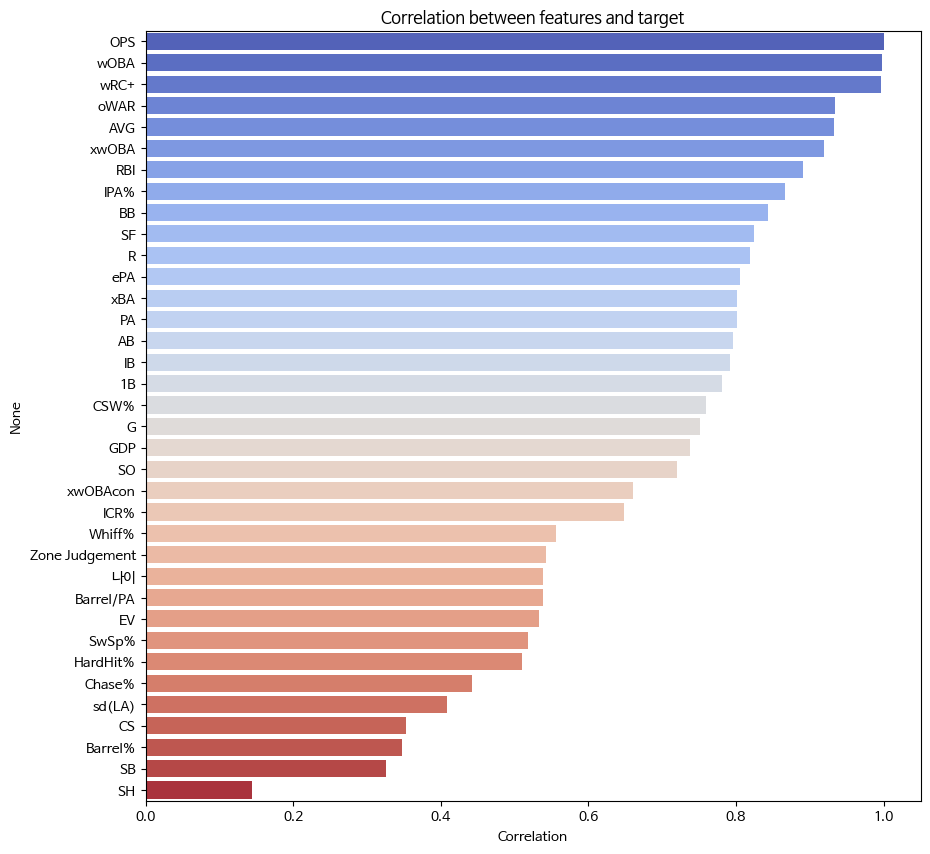

In [ ]:
plt.figure(figsize=(10,10))
colors = sns.color_palette("coolwarm", len(corr_with_target[corr_with_target >= 0.1]))

sns.barplot(x = corr_with_target[corr_with_target >= 0.1] , y = corr_with_target[corr_with_target >= 0.1].index, palette=colors).set_title('Correlation between features and target')
plt.xlabel('Correlation')

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# VIF 분석을 위한 데이터 준비 (연도, 이름 등 불필요한 변수 제거)
feature_columns = train_df.drop(columns=["OPS"]).copy()

# VIF 계산
vif_data = pd.DataFrame()
vif_data["Feature"] = feature_columns.columns
vif_data["VIF"] = [variance_inflation_factor(feature_columns.values, i) for i in range(len(feature_columns.columns))]

# VIF 결과 확인
print(vif_data.sort_values(by="VIF", ascending=False))

           Feature            VIF
4               PA  468196.627082
5              ePA  446083.273379
21            wOBA   37545.860220
18             OBP   20446.489184
6               AB   12616.806157
36           xwOBA    6605.884730
19             SLG    4836.325555
33            IPA%    3696.989804
35        xwOBAcon    3126.715279
22              EV    2197.308417
17             AVG    1989.507001
32            ICR%    1523.925058
34             xBA    1339.662819
20            wRC+     583.907563
27            CSW%     356.038831
37              1B     274.965313
25          Chase%     268.699730
11              BB     175.045925
23          sd(LA)     137.928361
15              SH      93.668384
26          Whiff%      90.640238
3                G      78.913360
24           SwSp%      67.620095
0               나이      65.470345
7                R      62.435625
13              SO      61.215106
8              RBI      60.760268
29        HardHit%      54.761261
31       Barre

In [ ]:
feature_columns = feature_columns.drop(columns=['PA','dWAR','ePA','AB','wOBA','xwOBAcon','IPA%','EV','AVG','ICR%','Chase%','sd(LA)','SH','Whiff%','G','Barrel/PA',
                                                'Barrel%','IB','Zone Judgement','SB','CS']).copy()

# VIF 계산
vif_data = pd.DataFrame()
vif_data["Feature"] = feature_columns.columns
vif_data["VIF"] = [variance_inflation_factor(feature_columns.values, i) for i in range(len(feature_columns.columns))]

# VIF 결과 확인
print(vif_data.sort_values(by="VIF", ascending=False))

     Feature         VIF
15     xwOBA  649.275813
8        OBP  492.916593
14       xBA  337.933000
9        SLG  233.613808
10      wRC+  150.091562
12      CSW%   99.377678
11     SwSp%   53.175759
16        1B   50.429983
0         나이   49.645084
3        RBI   41.068586
2          R   39.123431
4         BB   26.937007
13  HardHit%   23.299668
5         SO   18.872966
1       oWAR   11.377875
7         SF    6.403713
6        GDP    5.750805


In [ ]:
#다중공선성 제거, 핵심지표 유지
train_df = train_df.drop(columns=['PA','dWAR','ePA','AB','wOBA','xwOBAcon','IPA%','EV','AVG','ICR%','Chase%','sd(LA)','SH','Whiff%','G','Barrel/PA',
                                                'HardHit%','Barrel%','IB','Zone Judgement','SB','CS'])
test_df = test_df.drop(columns=['PA','dWAR','ePA','AB','wOBA','xwOBAcon','IPA%','EV','AVG','ICR%','Chase%','sd(LA)','SH','Whiff%','G','Barrel/PA',
                                                'HardHit%','Barrel%','IB','Zone Judgement','SB','CS'])

In [ ]:
print("Train Columns:", train_df.columns)
print("Test Columns:", test_df.columns)

Train Columns: Index(['나이', 'oWAR', 'R', 'RBI', 'BB', 'SO', 'GDP', 'SF', 'OBP', 'SLG', 'OPS',
       'wRC+', 'SwSp%', 'CSW%', 'xBA', 'xwOBA', '1B'],
      dtype='object')
Test Columns: Index(['나이', 'oWAR', 'R', 'RBI', 'BB', 'SO', 'GDP', 'SF', 'OBP', 'SLG', 'OPS',
       'wRC+', 'SwSp%', 'CSW%', 'xBA', 'xwOBA', '1B'],
      dtype='object')


In [ ]:
train_df

,나이,oWAR,R,RBI,BB,SO,GDP,SF,OBP,SLG,OPS,wRC+,SwSp%,CSW%,xBA,xwOBA,1B
0,35,3.91,55,67,45,53,18,7,0.361,0.478,0.839,122.4,33.6,24.4,0.298,0.374,78
1,36,1.86,38,66,41,58,21,3,0.330,0.409,0.739,102.0,33.4,27.2,0.279,0.348,69
2,37,3.60,60,77,49,65,17,5,0.366,0.445,0.811,123.5,40.0,26.4,0.302,0.375,91
3,21,6.72,76,102,103,85,7,8,0.450,0.521,0.971,168.7,31.4,24.0,0.296,0.397,122
4,22,-0.19,24,29,23,44,6,2,0.312,0.371,0.683,85.4,31.7,29.0,0.248,0.324,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,25,0.35,40,91,36,92,20,5,0.315,0.401,0.716,98.8,34.9,24.9,0.239,0.296,81
314,26,-0.48,19,26,18,50,6,3,0.296,0.322,0.618,70.5,33.5,28.8,0.231,0.309,28
315,33,2.41,74,56,46,92,11,4,0.358,0.402,0.760,107.9,34.3,27.3,0.276,0.340,104
316,34,2.07,59,64,53,99,17,2,0.335,0.380,0.715,97.1,34.8,25.4,0.252,0.320,98


In [ ]:

# 독립 변수(X) 설정 (OPS 제거)
X_train = train_df.drop(columns=["OPS"], errors="ignore")
y_train = train_df["OPS"]
X_test = test_df.drop(columns=["OPS"], errors="ignore")


In [ ]:
from sklearn.decomposition import PCA
import numpy as np


pca = PCA()
X_pca = pca.fit_transform(X_train)

# 설명 분산 비율 확인
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = explained_variance_ratio.cumsum()


# PCA 결과 데이터프레임 생성
pca_df = pd.DataFrame({
    "주성분": [f"PC{i+1}" for i in range(len(explained_variance_ratio))],
    "설명된 분산 비율": explained_variance_ratio,
    "누적 분산 비율": cumulative_variance_ratio
})


pca_df

,주성분,설명된 분산 비율,누적 분산 비율
0,PC1,7.405494e-01,0.740549
1,PC2,1.071606e-01,0.847710
2,PC3,8.247646e-02,0.930186
3,PC4,2.492942e-02,0.955116
4,PC5,1.968595e-02,0.974802
5,PC6,1.174578e-02,0.986548
6,PC7,6.416225e-03,0.992964
7,PC8,3.216909e-03,0.996181
8,PC9,2.091565e-03,0.998272
9,PC10,1.189254e-03,0.999462


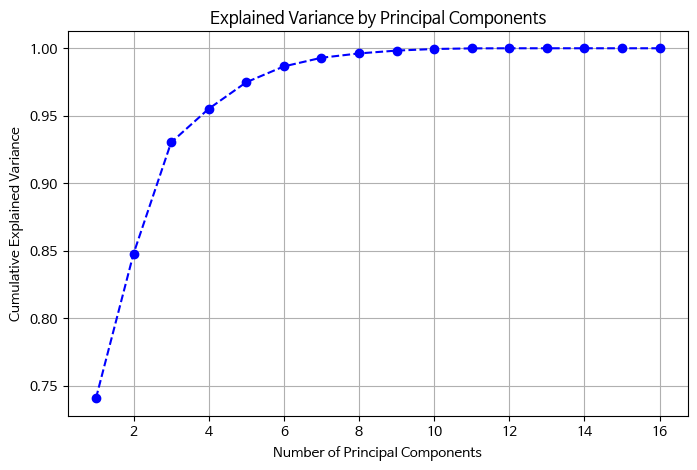

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# PCA 주성분별 설명력 확인
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

# 주성분별 설명력 시각화
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_variance_ratio, marker='o', linestyle='--', color='b')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance by Principal Components")
plt.grid()
plt.show()


In [ ]:
# 누적 설명 분산이 90% 이상 되는 PCA 개수 선택
n_components = (cumulative_variance_ratio >= 0.90).argmax() + 1
print(f"선택할 주성분 개수: {n_components}")

# PCA 변환 후 주요 주성분만 선택
pca_selected = PCA(n_components=n_components)
X_pca_selected = pca_selected.fit_transform(X_train)

# 변환된 데이터 크기 확인
print("PCA 적용 후 데이터 크기:", X_pca_selected.shape)


선택할 주성분 개수: 3
PCA 적용 후 데이터 크기: (307, 3)


In [ ]:
# 독립 변수(X_test) 설정 (OPS 제거)
X_test = test_df.drop(columns=["OPS"], errors="ignore")  # 테스트 데이터에도 동일 적용

#PCA 변환 적용 (훈련 데이터에서 학습한 PCA 사용)
X_test_pca_selected = pca_selected.transform(X_test)  # transform만 수행

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor, BayesianRidge, Lars
from sklearn.metrics import r2_score, mean_squared_error

# PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
X_test_pca_selected = X_test_pca_selected  # 테스트 데이터 (PCA 적용됨)

# 종속 변수 (타겟 변수)
y_train = train_df["OPS"]
y_test = test_df["OPS"]

# 모델 리스트 정의
models = {
    "Linear Regression": LinearRegression(),
    "Least Angle Regression (LARS)": Lars(),
    "Bayesian Ridge": BayesianRidge(),
    "Huber Regressor": HuberRegressor(),
    "Ridge Regression": Ridge(alpha=1.0)  # α 값 조정 가능
}

# 결과 저장 (R², MSE, RMSE)
results = {}

# 모델 학습 및 평가
for name, model in models.items():
    model.fit(X_train_pca_selected, y_train)  # PCA 변환된 데이터로 학습
    y_pred = model.predict(X_test_pca_selected)  # PCA 변환된 테스트 데이터로 예측

    # 평가 지표 계산
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    # 결과 저장
    results[name] = {"R²": r2, "MSE": mse, "RMSE": rmse}

    # 출력
    print(f"{name} R²: {r2:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}\n")

# 결과를 데이터프레임으로 변환
results_df = pd.DataFrame(results).T

# 결과 출력
print("\n📊 모델별 성능 비교")
print(results_df)


Linear Regression R²: 0.857, MSE: 0.003, RMSE: 0.052

Least Angle Regression (LARS) R²: 0.857, MSE: 0.003, RMSE: 0.052

Bayesian Ridge R²: 0.857, MSE: 0.003, RMSE: 0.052

Huber Regressor R²: 0.859, MSE: 0.003, RMSE: 0.051

Ridge Regression R²: 0.857, MSE: 0.003, RMSE: 0.052


📊 모델별 성능 비교
                                     R²       MSE      RMSE
Linear Regression              0.857447  0.002664  0.051609
Least Angle Regression (LARS)  0.857447  0.002664  0.051609
Bayesian Ridge                 0.857490  0.002663  0.051601
Huber Regressor                0.858779  0.002639  0.051368
Ridge Regression               0.857447  0.002664  0.051609


# ✅선형회귀 - 스태킹


**메타 모델 선택 기준**

개별 모델(Base Models)이 주로 선형 모델 → 비선형 모델을 메타 모델로 사용


개별 모델이 서로 다른 유형이라면, 중립적인 선형 모델이 좋을 수도 있음


데이터 크기와 복잡도에 따라 다르게 선택 가능

In [ ]:
from sklearn.ensemble import StackingRegressor

#  PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
X_test_pca_selected = X_test_pca_selected  # 테스트 데이터 (PCA 적용됨)

#  종속 변수 (타겟 변수)
y_train = train_df["OPS"]
y_test = test_df["OPS"]

# 개별 회귀 모델 (Base Learners)
base_models = [
    ('Linear Regression', LinearRegression()),
    ('Least Angle Regression (LARS)', Lars()),
    ('Bayesian Ridge', BayesianRidge()),
    ('Huber Regressor', HuberRegressor()),
    ('Ridge Regression', Ridge(alpha=1.0))  # α 값 조정 가능
]

# 스태킹 회귀 모델 (최종 메타 모델: Linear Regression 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=LinearRegression()  # 메타 모델 (블렌더)
)

# 모델 학습
stacking_model.fit(X_train_pca_selected, y_train)

# 예측 수행
y_pred = stacking_model.predict(X_test_pca_selected)

# 성능 평가
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# 결과 출력
print(f"Stacking Regressor R²: {r2:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}")


Stacking Regressor R²: 0.859, MSE: 0.003, RMSE: 0.051


In [ ]:
#  훈련 데이터 예측 및 평가
y_train_pred = stacking_model.predict(X_train_pca_selected)
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)

# 테스트 데이터 예측 및 평가
y_test_pred = stacking_model.predict(X_test_pca_selected)
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)

# 결과 출력
print(f"Train 성능: R²: {train_r2:.3f}, MSE: {train_mse:.3f}, RMSE: {train_rmse:.3f}")
print(f"Test 성능: R²: {test_r2:.3f}, MSE: {test_mse:.3f}, RMSE: {test_rmse:.3f}")

# 과적합 여부 판단
gap = abs(train_r2 - test_r2)

if gap > 0.1:
    print("Train과 Test 성능 차이 큼")


Train 성능: R²: 0.964, MSE: 0.001, RMSE: 0.023
Test 성능: R²: 0.859, MSE: 0.003, RMSE: 0.051
Train과 Test 성능 차이 큼


In [ ]:
from sklearn.model_selection import cross_val_score

#  5-Fold Cross Validation 수행 (훈련 데이터에서만 적용)
cv_scores = cross_val_score(stacking_model, X_train_pca_selected, y_train, cv=5, scoring='r2')

#  교차 검증 결과 출력
print(f"Cross Validation R² Scores: {cv_scores}")
print(f"평균 R² (교차 검증): {cv_scores.mean():.3f}")

# 테스트 데이터 성능 확인
r2_test = r2_score(y_test, stacking_model.predict(X_test_pca_selected))
print(f"테스트 데이터 R²: {r2_test:.3f}")

# 과적합 여부 판단 (테스트 R²이 교차 검증 평균보다 0.05 낮으면 과적합 가능성)
if r2_test < cv_scores.mean() - 0.05:
    print("과적합 가능성이 있음")



Cross Validation R² Scores: [0.94423882 0.95083747 0.96820755 0.97331675 0.95465885]
평균 R² (교차 검증): 0.958
테스트 데이터 R²: 0.859
과적합 가능성이 있음!


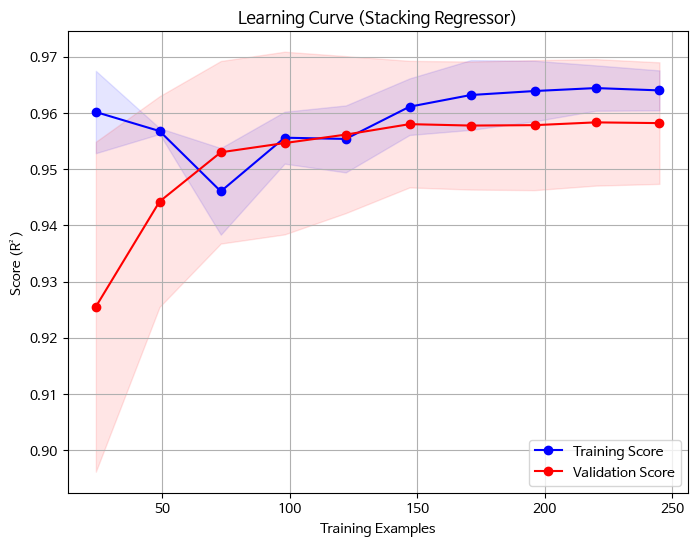

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
y_train = train_df["OPS"]

# 스태킹 회귀 모델 (최종 메타 모델: Linear Regression 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=LinearRegression()  # 메타 모델 (블렌더)
)

# 학습 곡선 계산 (5-Fold Cross Validation)
train_sizes, train_scores, test_scores = learning_curve(
    stacking_model, X_train_pca_selected, y_train, cv=5,
    scoring="r2", train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)

# 평균 및 표준편차 계산
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 학습 곡선 시각화
plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', label="Training Score", color="blue")
plt.plot(train_sizes, test_mean, 'o-', label="Validation Score", color="red")

# 신뢰구간 (표준편차)
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color="blue", alpha=0.1)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, color="red", alpha=0.1)

plt.xlabel("Training Examples")
plt.ylabel("Score (R²)")
plt.title("Learning Curve (Stacking Regressor)")
plt.legend()
plt.grid()
plt.show()



# ✅Ridge - 스태킹 ✔

In [ ]:
from sklearn.ensemble import StackingRegressor

#  PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
X_test_pca_selected = X_test_pca_selected  # 테스트 데이터 (PCA 적용됨)

#  종속 변수 (타겟 변수)
y_train = train_df["OPS"]
y_test = test_df["OPS"]

# 개별 회귀 모델 (Base Learners)
base_models = [
    ('Linear Regression', LinearRegression()),
    ('Least Angle Regression (LARS)', Lars()),
    ('Bayesian Ridge', BayesianRidge()),
    ('Huber Regressor', HuberRegressor()),
    ('Ridge Regression', Ridge(alpha=1.0))  # α 값 조정 가능
]

# 스태킹 회귀 모델 (최종 메타 모델: 릿지 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0)  # L2 정규화 적용
)

# 모델 학습
stacking_model.fit(X_train_pca_selected, y_train)

# 예측 수행
y_pred = stacking_model.predict(X_test_pca_selected)

# 성능 평가
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# 결과 출력
print(f"Stacking Regressor R²: {r2:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}")


Stacking Regressor R²: 0.853, MSE: 0.003, RMSE: 0.052




*   L2 정규화를 적용하여 다중공선성 문제 완화
*   개별 모델들이 비슷한 패턴을 가질 시 릿지가 가중치를 적절히 조절 가능함


*   선형적인 결합만 수행






In [ ]:
# 훈련 데이터 예측 및 평가
y_train_pred = stacking_model.predict(X_train_pca_selected)
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)

# 테스트 데이터 예측 및 평가
y_test_pred = stacking_model.predict(X_test_pca_selected)
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)

# 결과 출력
print(f"Train 성능: R²: {train_r2:.3f}, MSE: {train_mse:.3f}, RMSE: {train_rmse:.3f}")
print(f"Test 성능: R²: {test_r2:.3f}, MSE: {test_mse:.3f}, RMSE: {test_rmse:.3f}")

# 과적합 여부 판단
gap = abs(train_r2 - test_r2)

if gap > 0.1:
    print("Train과 Test 성능 차이 큼")

Train 성능: R²: 0.962, MSE: 0.001, RMSE: 0.024
Test 성능: R²: 0.853, MSE: 0.003, RMSE: 0.052
Train과 Test 성능 차이 큼


In [ ]:
from sklearn.model_selection import cross_val_score

# K-Fold Cross Validation (5-Fold)
cv_scores = cross_val_score(stacking_model, X_pca_selected, y_train, cv=5, scoring='r2')

print(f"Cross Validation R² Scores: {cv_scores}")
print(f"평균 R²: {cv_scores.mean():.3f}")

# 과적합 여부 확인
if r2_test < cv_scores.mean() - 0.05:  # 테스트 R²이 교차 검증 평균보다 0.05 낮으면 과적합 가능성
    print("과적합 가능성 있음")

Cross Validation R² Scores: [0.93755961 0.9561979  0.96216621 0.96804297 0.95203171]
평균 R²: 0.955
과적합 가능성 있음


**랜덤포레스트, xgb를 메타모델로 하면 과적합 발생**

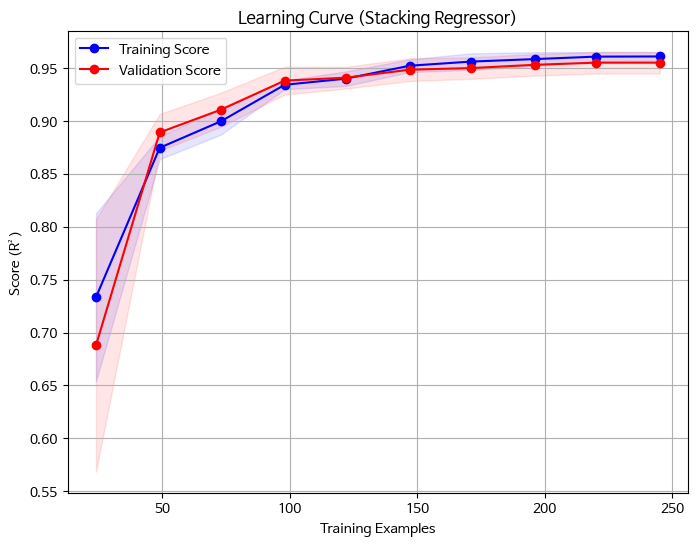

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
y_train = train_df["OPS"]

# 스태킹 회귀 모델 (최종 메타 모델: 릿지 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0)  # L2 정규화 적용
)

# 학습 곡선 계산 (5-Fold Cross Validation)
train_sizes, train_scores, test_scores = learning_curve(
    stacking_model, X_train_pca_selected, y_train, cv=5,
    scoring="r2", train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)

#평균 및 표준편차 계산
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

#학습 곡선 시각화
plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', label="Training Score", color="blue")
plt.plot(train_sizes, test_mean, 'o-', label="Validation Score", color="red")

#신뢰구간 (표준편차)
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color="blue", alpha=0.1)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, color="red", alpha=0.1)

plt.xlabel("Training Examples")
plt.ylabel("Score (R²)")
plt.title("Learning Curve (Stacking Regressor)")
plt.legend()
plt.grid()
plt.show()



# ✅ huber regressor - 스태킹


일반적인 선형회귀와 이상치에 강한 로버스트 회귀의 장점을 결합한 회귀모델

 → 이상치가 많고 선형적인 관계를 학습할 때 효과적임
- mse(평균제곱오차) 대신 huber 손실함수(Huber Loss) 를 사용하여 이상치를 완화하는 특징이 있음
- 오차가 작을 때 : MSE 처럼 작동
- 오차가 클 때 : MAE 처럼 작동
:

In [ ]:
from sklearn.ensemble import StackingRegressor

#  PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
X_test_pca_selected = X_test_pca_selected  # 테스트 데이터 (PCA 적용됨)

#  종속 변수 (타겟 변수)
y_train = train_df["OPS"]
y_test = test_df["OPS"]

# 개별 회귀 모델 (Base Learners)
base_models = [
    ('Linear Regression', LinearRegression()),
    ('Least Angle Regression (LARS)', Lars()),
    ('Bayesian Ridge', BayesianRidge()),
    ('Huber Regressor', HuberRegressor()),
    ('Ridge Regression', Ridge(alpha=1.0))  # α 값 조정 가능
]

# 스태킹 회귀 모델 (메타 모델: Huber Regressor 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=HuberRegressor()  # 메타 모델을 Huber Regressor로 설정
)

# 모델 학습
stacking_model.fit(X_train_pca_selected, y_train)

# 예측 수행
y_pred = stacking_model.predict(X_test_pca_selected)

# 성능 평가
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# 결과 출력
print(f"Stacking Regressor R²: {r2:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}")


Stacking Regressor R²: 0.861, MSE: 0.003, RMSE: 0.051


In [ ]:
# 훈련 데이터 예측 및 평가
y_train_pred = stacking_model.predict(X_train_pca_selected)
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)

# 테스트 데이터 예측 및 평가
y_test_pred = stacking_model.predict(X_test_pca_selected)
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)

# 결과 출력
print(f"train 성능: R²: {train_r2:.3f}, MSE: {train_mse:.3f}, RMSE: {train_rmse:.3f}")
print(f"Test 성능: R²: {test_r2:.3f}, MSE: {test_mse:.3f}, RMSE: {test_rmse:.3f}")

# 과적합 여부 판단
gap = abs(train_r2 - test_r2)

if gap > 0.1:
    print("Train과 Test 성능 차이 큼")

train 성능: R²: 0.964, MSE: 0.001, RMSE: 0.023
Test 성능: R²: 0.861, MSE: 0.003, RMSE: 0.051
Train과 Test 성능 차이 큼


In [ ]:
from sklearn.model_selection import cross_val_score

# K-Fold Cross Validation (5-Fold)
cv_scores = cross_val_score(stacking_model, X_pca_selected, y_train, cv=5, scoring='r2')

print(f"Cross Validation R² Scores: {cv_scores}")
print(f"평균 R²: {cv_scores.mean():.3f}")

# 과적합 여부 확인
if r2_test < cv_scores.mean() - 0.05:  # 테스트 R²이 교차 검증 평균보다 0.05 낮으면 과적합 가능성
    print("과적합 가능성 있음")

Cross Validation R² Scores: [0.94361304 0.9506067  0.9690496  0.97318498 0.95468313]
평균 R²: 0.958
과적합 가능성 있음


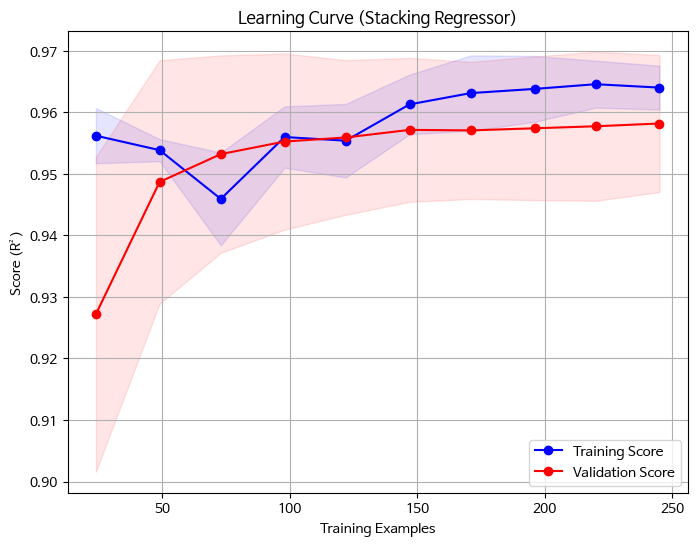

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# PCA 변환된 데이터 사용
X_train_pca_selected = X_pca_selected  # 훈련 데이터 (이미 PCA 적용됨)
y_train = train_df["OPS"]

# 스태킹 회귀 모델 (메타 모델: Huber Regressor 사용)
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=HuberRegressor()  # 메타 모델을 Huber Regressor로 설정
)

# 학습 곡선 계산 (5-Fold Cross Validation)
train_sizes, train_scores, test_scores = learning_curve(
    stacking_model, X_train_pca_selected, y_train, cv=5,
    scoring="r2", train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)

# 평균 및 표준편차 계산
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 학습 곡선 시각화
plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', label="Training Score", color="blue")
plt.plot(train_sizes, test_mean, 'o-', label="Validation Score", color="red")

# 신뢰구간 (표준편차)
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color="blue", alpha=0.1)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, color="red", alpha=0.1)

plt.xlabel("Training Examples")
plt.ylabel("Score (R²)")
plt.title("Learning Curve (Stacking Regressor)")
plt.legend()
plt.grid()
plt.show()

